# 02 — VAERS: EDA and preprocessing

From the official VAERS files to the submitted dataset `vaers_v11b.csv`, with the evidence behind every rule.

- **Part A — raw data:** what we found, and which problem each finding exposed.
- **Part B — preprocessing:** the pipeline run end to end, step by step, with rows kept at each step.
- **Part C — the final dataset:** columns, signal, leakage checks.

**Input:** `2019VAERSData.zip`, `2023VAERSData.zip`, `2024VAERSData.zip` from [vaers.hhs.gov](https://vaers.hhs.gov/data/datasets.html), in `research/data/vaers_raw/`. 2019 is a pre-COVID year with mixed vaccines; 2023–2024 are recent years after the COVID-vaccine reporting surge of 2021–2022. CPU, about 6 minutes.

In [1]:
import sys, io, re, time, hashlib, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT))
from research.scripts.vaers import build_vaers as bv, refine_v9 as rv, build_v11b as b11

RAW = sorted((ROOT / "research/data/vaers_raw").glob("20*VAERSData.zip"))
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e7e6e2"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlecolor": INK})
pd.set_option("display.precision", 3); pd.set_option("display.max_colwidth", 120)

t = bv.load_year_files(RAW)
raw = t["DATA"].drop_duplicates("VAERS_ID").copy()
raw["serious"] = raw[bv.OUTCOME_FLAGS].fillna("").eq("Y").any(axis=1)
raw["year"] = pd.to_datetime(raw.RECVDATE, errors="coerce").dt.year
raw["manufacturer_report"] = raw.SPLTTYPE.fillna("").str.strip() != ""
first_vax = t["VAX"].drop_duplicates("VAERS_ID").set_index("VAERS_ID").VAX_TYPE
raw["vax_type"] = raw.VAERS_ID.map(first_vax)
print(f"{[p.name for p in RAW]}\n{len(raw):,} unique reports, {raw.serious.mean():.1%} serious, "
      f"{t['DATA'].shape[1]} raw columns")

['2019VAERSData.zip', '2023VAERSData.zip', '2024VAERSData.zip']
208,309 unique reports, 12.8% serious, 36 raw columns


## Part A — the raw data

### A1. Reports and the label

`serious` = 1 if any of the six outcome flags is set: died, life-threatening, hospitalised, prolonged stay, disability, birth defect. This is the FDA definition of a serious adverse event.

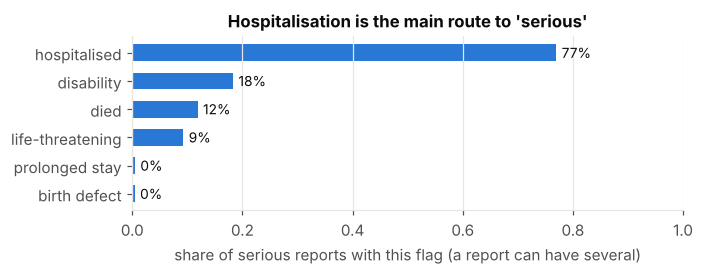

,reports,serious,manufacturer_reports
year,,,
2019,"49,786",6.2%,39.6%
2023,"106,565",18.0%,37.2%
2024,"51,958",8.6%,33.8%


In [2]:
by_year = raw.groupby("year").agg(reports=("VAERS_ID", "size"), serious=("serious", "mean"),
                                  manufacturer_reports=("manufacturer_report", "mean"))
flags = (raw.loc[raw.serious, bv.OUTCOME_FLAGS].fillna("").eq("Y").mean().sort_values())
names = {"DIED": "died", "L_THREAT": "life-threatening", "HOSPITAL": "hospitalised", "X_STAY": "prolonged stay",
         "DISABLE": "disability", "BIRTH_DEFECT": "birth defect"}
fig, ax = plt.subplots(figsize=(6.5, 2.6))
ax.barh([names[f] for f in flags.index], flags.values, color=BLUE, height=0.6)
for i, v in enumerate(flags.values):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 1); ax.set_xlabel("share of serious reports with this flag (a report can have several)")
ax.set_title("Hospitalisation is the main route to 'serious'"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
by_year.style.format({"reports": "{:,}", "serious": "{:.1%}", "manufacturer_reports": "{:.1%}"})

**Insight.** 77% of serious reports involve a hospital stay, so any text that reveals hospital care reveals the label. That is the central leakage risk of this dataset.

### A2. Manufacturer reports

In [3]:
m = raw.groupby("manufacturer_report").serious.agg(["size", "mean"]).rename(index={False: "direct reports", True: "manufacturer reports"})
m.columns = ["reports", "serious rate"]
m.style.format({"reports": "{:,}", "serious rate": "{:.1%}"})

,reports,serious rate
manufacturer_report,,
direct reports,"131,372",17.0%
manufacturer reports,"76,937",5.6%


**Insight.** Manufacturer reports are 37% of all reports, use templated text, and have a very different serious rate (5.6% vs 17.0%). Keeping them would let a model learn *who reported* rather than *what happened*: they are dropped.

### A3. Late-onset COVID reports

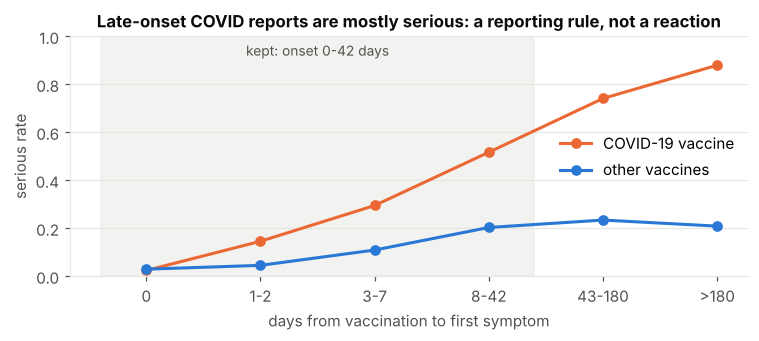

In [4]:
direct = raw[~raw.manufacturer_report].copy()
d = pd.to_numeric(direct.NUMDAYS, errors="coerce")
direct["onset"] = pd.cut(d, [-1, 0, 2, 7, 42, 180, 1e9], labels=["0", "1-2", "3-7", "8-42", "43-180", ">180"]).astype(str).replace("nan", "unknown")
direct["vaccine"] = np.where(direct.vax_type.astype(str).str.startswith("COVID"), "COVID-19 vaccine", "other vaccines")
rate = direct.groupby(["onset", "vaccine"]).serious.mean().unstack().reindex(["0", "1-2", "3-7", "8-42", "43-180", ">180", "unknown"])

fig, ax = plt.subplots(figsize=(7, 3.2))
for col, c in [("COVID-19 vaccine", ORANGE), ("other vaccines", BLUE)]:
    ax.plot(rate.index, rate[col], marker="o", color=c, lw=2, label=col)
ax.axvspan(-0.4, 3.4, color=GRID, alpha=0.5, zorder=0); ax.text(1.5, 0.92, "kept: onset 0-42 days", ha="center", color=INK2, fontsize=9)
ax.set_ylim(0, 1.0); ax.set_xlabel("days from vaccination to first symptom"); ax.set_ylabel("serious rate")
ax.set_title("Late-onset COVID reports are mostly serious: a reporting rule, not a reaction")
ax.legend(frameon=False, loc="center right"); ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

**Insight.** COVID-19 cases in vaccinated people (breakthrough infections) had to be reported mainly when they were severe, weeks or months after vaccination. In the first build, onset delay alone scored AUROC 0.877. Fix: keep reactions with onset 0–42 days (or unknown) and drop infection and vaccine-failure reports.

### A4. Missing values in the raw fields

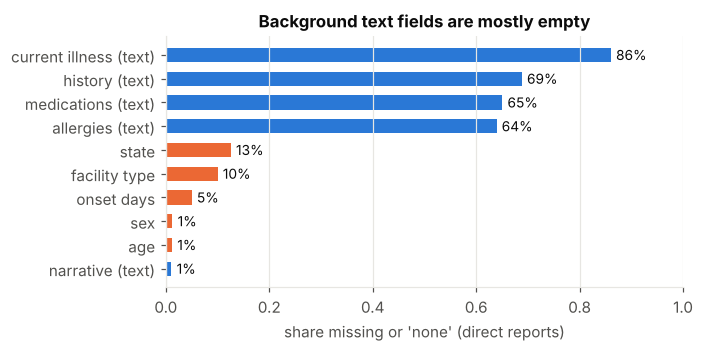

In [5]:
fields = {"AGE_YRS": "age", "SEX": "sex", "STATE": "state", "NUMDAYS": "onset days", "V_ADMINBY": "facility type",
          "HISTORY": "history (text)", "CUR_ILL": "current illness (text)", "OTHER_MEDS": "medications (text)",
          "ALLERGIES": "allergies (text)", "SYMPTOM_TEXT": "narrative (text)"}
def is_missing(s):
    v = s.fillna("").astype(str).str.strip().str.lower()
    return v.isin(["", "u", "unk", "none", "n/a", "na", "no", "none reported", "unknown", "nan"])
miss = pd.Series({lab: is_missing(direct[c]).mean() for c, lab in fields.items()}).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3.3))
ax.barh(miss.index, miss.values, color=[BLUE if "(text)" in i else ORANGE for i in miss.index], height=0.6)
for i, v in enumerate(miss.values):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 1); ax.set_xlabel("share missing or 'none' (direct reports)"); ax.grid(axis="y", visible=False)
ax.set_title("Background text fields are mostly empty"); plt.tight_layout(); plt.show()

**Insight.** The four background fields are empty in 64–86% of reports. As four columns, most of the text would be "none reported", so they are merged into one `patient_background` column (empty in 33%). Structured fields are mostly complete.

### A5. What the full narrative reveals

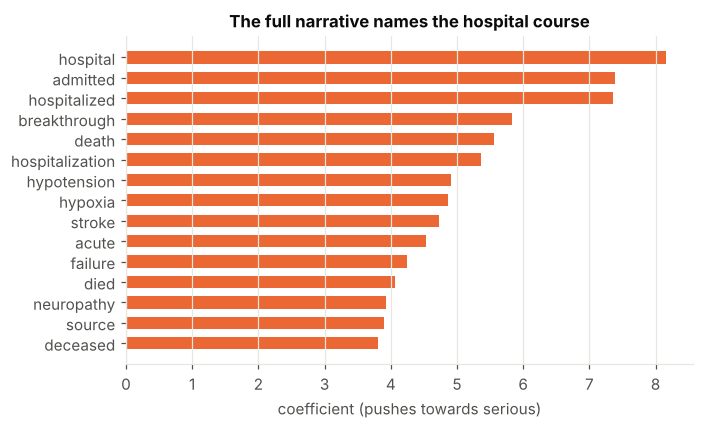

In [6]:
sample = direct.sample(30000, random_state=42)
vec = TfidfVectorizer(min_df=20, sublinear_tf=True, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b")
Xn = vec.fit_transform(sample.SYMPTOM_TEXT.fillna(""))
lr = LogisticRegression(C=1.0, max_iter=3000).fit(Xn, sample.serious)
top = pd.Series(lr.coef_[0], index=vec.get_feature_names_out()).nlargest(15)[::-1]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.barh(top.index, top.values, color=ORANGE, height=0.6); ax.grid(axis="y", visible=False)
ax.set_xlabel("coefficient (pushes towards serious)")
ax.set_title("The full narrative names the hospital course")
plt.tight_layout(); plt.show()

**Insight.** The full narrative's top words name the outcome directly (*hospital, admitted, hospitalized, death, died, deceased*) or the reporting route (*breakthrough*): the label in other words. Fix: keep only the narrative's *opening*, cut at the first sentence about care, testing, treatment, outcome, chart codes or vital signs (at most 3 sentences).

## Part B — preprocessing

### B1. Run the full pipeline

The same code as `research/scripts/vaers/build_v11b.py`; each stage's output hash is checked against the frozen file.

In [7]:
t0 = time.time()
bv.MAX_ONSET_SENTENCES = 3
bv.ENRICHED_POSITIVE_SHARE = 0.01            # no sampling at this stage: every eligible report is kept
cohort, meta = bv.build(RAW, "v9", 60000, 42)
c = meta["counts"]
rawtab = t["DATA"].drop_duplicates("VAERS_ID").copy(); rawtab.VAERS_ID = rawtab.VAERS_ID.map(rv.canonical_id)
refined, ledger = rv.refine(b11.as_str(cohort), rawtab.set_index("VAERS_ID"))
full = refined[ledger.eligible.to_numpy()].reset_index(drop=True)
v11a = pd.read_csv(io.BytesIO(b11.csv_bytes(b11.matched_controls(full))), keep_default_na=False, dtype=str)
assert hashlib.sha256(b11.csv_bytes(v11a)).hexdigest() == b11.SHA_V11A
edits = pd.read_csv(b11.LEDGER, keep_default_na=False, dtype=str)
v11b = b11.apply_care_boundary_3(v11a, edits)
assert hashlib.sha256(b11.csv_bytes(v11b)).hexdigest() == b11.SHA_V11B
df = v11b
print(f"rebuilt v11b in {time.time() - t0:.0f} s: {len(df):,} reports, hash matches the submitted file")

rebuilt v11b in 145 s: 18,859 reports, hash matches the submitted file


### B2. Rows kept at each step

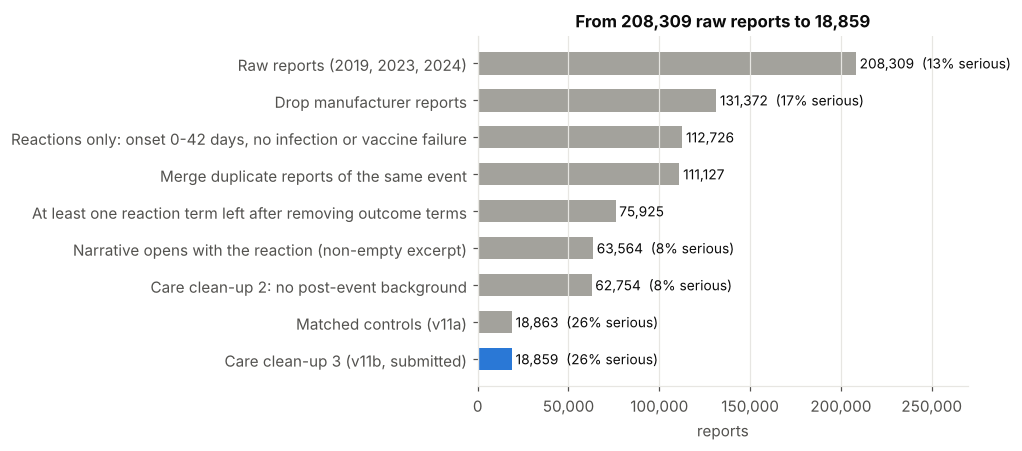

In [8]:
steps = [
 ("Raw reports (2019, 2023, 2024)", c["raw_reports"], raw.serious.mean()),
 ("Drop manufacturer reports", c["after_dropping_manufacturer_reports"], direct.serious.mean()),
 ("Reactions only: onset 0-42 days, no infection or vaccine failure", c["after_scope_vaccine_reactions"], None),
 ("Merge duplicate reports of the same event", c["after_event_dedup"], None),
 ("At least one reaction term left after removing outcome terms", c["with_symptom_terms"], None),
 ("Narrative opens with the reaction (non-empty excerpt)", c["after_exact_duplicate_rows"], cohort.serious.astype(int).mean()),
 ("Care clean-up 2: no post-event background", len(full), full.serious.astype(int).mean()),
 ("Matched controls (v11a)", len(v11a), v11a.serious.astype(int).mean()),
 ("Care clean-up 3 (v11b, submitted)", len(df), df.serious.astype(int).mean()),
]
f = pd.DataFrame(steps, columns=["step", "reports", "serious"])
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(f.step[::-1], f.reports[::-1], color=[BLUE] + [GRAY] * (len(f) - 1), height=0.6)
for i, r in enumerate(f[::-1].itertuples()):
    lab = f"{r.reports:,}" + (f"  ({r.serious:.0%} serious)" if r.serious == r.serious and r.serious is not None else "")
    ax.text(r.reports + 2000, i, lab, va="center", fontsize=9, color=INK)
ax.set_xlim(0, 270000); ax.set_xlabel("reports"); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title("From 208,309 raw reports to 18,859"); plt.tight_layout(); plt.show()

In [9]:
pd.DataFrame([
 ("Manufacturer reports", c["raw_reports"] - c["after_dropping_manufacturer_reports"], "Templated text, different serious rate: a reporter shortcut (A2)"),
 ("Infection / vaccine-failure reports", c["removed_infection_or_failure_reports"], "Seriousness follows the reporting rule (A3)"),
 ("Onset over 42 days", c["removed_onset_over_42_days"], "Outside the usual reaction window (A3)"),
 ("Duplicate reports of one event", c["dedup_reports_removed"] + c["event_dedup_reports_removed"], "Same dates, patient, vaccine, lot and symptoms"),
 ("No reaction term left", c["after_event_dedup"] - c["with_symptom_terms"], "Only outcome / care / administration terms"),
 ("Narrative starts with care or outcome", c["with_symptom_terms"] - c["with_onset_excerpt"], f"Emptiness itself leaked the label: {c['narrative_onset_empty_share_by_label']['serious']:.0%} of serious vs {c['narrative_onset_empty_share_by_label']['not_serious']:.0%} of others"),
 ("Post-event background or empty excerpt after clean-up 2", len(cohort) - len(full), "Background describing the reaction itself"),
 ("Non-serious reports not needed as matched controls", len(full) - len(v11a), "Up to 3 controls per serious report, same vaccine, year, age band, sex"),
 ("Excerpt empty after clean-up 3", len(v11a) - len(df), "Only treatment text was left"),
], columns=["removed", "reports", "why"]).set_index("removed").style.format({"reports": "{:,}"})

,reports,why
removed,,
Manufacturer reports,"76,937","Templated text, different serious rate: a reporter shortcut (A2)"
Infection / vaccine-failure reports,"8,054",Seriousness follows the reporting rule (A3)
Onset over 42 days,"10,592",Outside the usual reaction window (A3)
Duplicate reports of one event,"1,599","Same dates, patient, vaccine, lot and symptoms"
No reaction term left,"35,202",Only outcome / care / administration terms
Narrative starts with care or outcome,"12,360",Emptiness itself leaked the label: 36% of serious vs 19% of others
Post-event background or empty excerpt after clean-up 2,810,Background describing the reaction itself
Non-serious reports not needed as matched controls,"43,891","Up to 3 controls per serious report, same vaccine, year, age band, sex"
Excerpt empty after clean-up 3,4,Only treatment text was left


**Insight.** Most rows are removed by rules that protect the label (manufacturer reports, late onset, care-only narratives). The matching step keeps every serious report and samples controls, which sets the class balance to 26%.

### B3. Which columns, and why

In [10]:
pd.DataFrame([
 ("Used: 12 structured", "age, sex, state, onset days, vaccine type, manufacturer, dose, route, site, number of vaccines, facility type, report year", "Known when the report is filed"),
 ("Used: 2 text", "patient background (history, illness, medications, allergies merged) + opening of the reaction narrative", "Free text the table does not have"),
 ("Label only", "DIED, L_THREAT, HOSPITAL, X_STAY, DISABLE, BIRTH_DEFECT", "These define `serious`; never inputs"),
 ("Dropped: after the event", "ER / office visits, HOSPDAYS, RECOVD, DATEDIED, LAB_DATA", "Outcome or care that reveals the label"),
 ("Dropped: rest of the narrative", "SYMPTOM_TEXT after its opening", "Hospital course (A5)"),
 ("Dropped: raw dates", "RECVDATE, VAX_DATE, ONSET_DATE, TODAYS_DATE, RPT_DATE", "Replaced by onset_days and report_year"),
 ("Dropped: report artefacts", "SPLTTYPE, FORM_VERS, VAX_LOT, VAX_NAME, PRIOR_VAX, V_FUNDBY", "Reporter type, form version, identifiers, duplicates of vaccine fields"),
], columns=["group", "VAERS fields", "why"]).set_index("group")

,VAERS fields,why
group,,
Used: 12 structured,"age, sex, state, onset days, vaccine type, manufacturer, dose, route, site, number of vaccines, facility type, repor...",Known when the report is filed
Used: 2 text,"patient background (history, illness, medications, allergies merged) + opening of the reaction narrative",Free text the table does not have
Label only,"DIED, L_THREAT, HOSPITAL, X_STAY, DISABLE, BIRTH_DEFECT",These define `serious`; never inputs
Dropped: after the event,"ER / office visits, HOSPDAYS, RECOVD, DATEDIED, LAB_DATA",Outcome or care that reveals the label
Dropped: rest of the narrative,SYMPTOM_TEXT after its opening,Hospital course (A5)
Dropped: raw dates,"RECVDATE, VAX_DATE, ONSET_DATE, TODAYS_DATE, RPT_DATE",Replaced by onset_days and report_year
Dropped: report artefacts,"SPLTTYPE, FORM_VERS, VAX_LOT, VAX_NAME, PRIOR_VAX, V_FUNDBY","Reporter type, form version, identifiers, duplicates of vaccine fields"


### B4. Missing values and duplicates in the final dataset

In [11]:
NUM = ["age_years", "onset_days", "n_vaccines", "report_year"]
CAT = ["sex", "state", "vax_type", "vax_manu", "vax_dose_series", "vax_route", "vax_site", "admin_by"]
TEXT = ["narrative_onset", "patient_background"]
rows = []
for col in NUM + CAT + TEXT:
    v = df[col]
    n = int((v == "").sum()) if col in NUM else int(v.isin(["U", "UNK", "UNKNOWN", "none reported"]).sum())
    how = ("left empty, the benchmark imputes it (impossible ages / delays also set empty)" if col in NUM else
           "'none reported'" if col in TEXT else "kept as its own category (U / UNK / UNKNOWN)")
    rows.append({"column": col, "missing": n, "share": f"{n / len(df):.1%}", "handled as": how})
miss_final = pd.DataFrame(rows).set_index("column").sort_values("missing", ascending=False)
X = df.drop(columns=["report_id", "serious"])
print(f"Duplicates removed in the build: {c['dedup_reports_removed'] + c['event_dedup_reports_removed']:,} reports "
      f"(label conflicts inside merged groups: {c['dedup_clusters_with_label_conflict'] + c['event_dedup_pairs_with_label_conflict']})")
print(f"Final file: {df.report_id.duplicated().sum()} duplicate ids, {X.duplicated().sum()} identical input rows "
      f"(with conflicting labels: {int((df.groupby(list(X.columns)).serious.nunique() > 1).sum())})")
miss_final[miss_final.missing > 0]

Duplicates removed in the build: 1,599 reports (label conflicts inside merged groups: 2)
Final file: 0 duplicate ids, 3 identical input rows (with conflicting labels: 0)


,missing,share,handled as
column,,,
patient_background,6205,32.9%,'none reported'
vax_dose_series,4449,23.6%,kept as its own category (U / UNK / UNKNOWN)
vax_site,2427,12.9%,kept as its own category (U / UNK / UNKNOWN)
vax_route,2260,12.0%,kept as its own category (U / UNK / UNKNOWN)
admin_by,1359,7.2%,kept as its own category (U / UNK / UNKNOWN)
state,1193,6.3%,kept as its own category (U / UNK / UNKNOWN)
onset_days,999,5.3%,"left empty, the benchmark imputes it (impossible ages / delays also set empty)"
vax_type,580,3.1%,kept as its own category (U / UNK / UNKNOWN)
age_years,175,0.9%,"left empty, the benchmark imputes it (impossible ages / delays also set empty)"


**Insight.** Nothing is dropped for being missing: "unknown" is information (for example, dose series is unknown in a quarter of reports). Duplicates are merged before sampling, so no report appears twice.

### B5. The text, before and after cleaning

In [12]:
src = rawtab.set_index("VAERS_ID").SYMPTOM_TEXT
ex = df.sample(4, random_state=3)
pd.DataFrame({"raw narrative (start)": [str(src.get(r, ""))[:260] + " …" for r in ex.report_id],
              "kept excerpt": ex.narrative_onset.to_numpy(), "serious": ex.serious.to_numpy()})

,raw narrative (start),kept excerpt,serious
0,"Patient got the IMZ high up and behind the arm. Immediately felt pain, and shortly after redness. Just took ibuprofe...","Patient got the IMZ high up and behind the arm. Immediately felt pain, and shortly after redness. Just",0
1,"From January 26, 2021 through Feb 23, 2021 I had the following reaction: no energy, unable to sleep, high heart rate...","From January 26, through Feb 23, I had the following reaction: no energy, unable to sleep, high heart rate, body ach...",1
2,"Fever, hypertension and confusion …","Fever, hypertension and confusion",0
3,"On October 26,, 2022, I had symptoms of numbness & tingling in my right hand and above my lip (right side only). S...","On October 26,, , I had symptoms of numbness & tingling in my right hand and above my lip (right side only). Symptom...",1


In [13]:
cut = edits[edits.action == "truncate"].sample(5, random_state=1)
kept = v11a.set_index("report_id").narrative_onset
pd.DataFrame({"kept": [kept[r][: int(k)] for r, k in zip(cut.report_id, cut.kept_chars)],
              "removed in clean-up 3": cut.removed_text.str[:120].to_numpy()})

,kept,removed in clean-up 3
0,"Patient reports rash following COVID vaccine, lasting nearly 7 days.",She reports no success with Benadryl but is now using hydrocortisone.
1,"Headache, fever, fatigue, myalgia, chills, shaking, weakness, arthralgia fingers, arms, shoulders, back, legs, lack ...",Tylenol every 4 hours Symptoms continue
2,Intermittent fevers for past 24 hours. Max temp 102.,Temp does respond to tylenol.
3,"On , rash noted at injection site.",Applied Benadryl Cream. Soaked clothing with perspiration during sleep.
4,Patient's arms became swollen up the day after getting both shots. Patient returned to pharmacy on to inform us that...,We suggested some benadryl.


**Insight.** The excerpt keeps the reporter's description of the reaction and stops before the care story. Clean-up 3 only ever cuts the end of an excerpt (503 edits: medication, treatment and procedure phrases); it never rewrites or adds text.

### B6. What matched controls changed

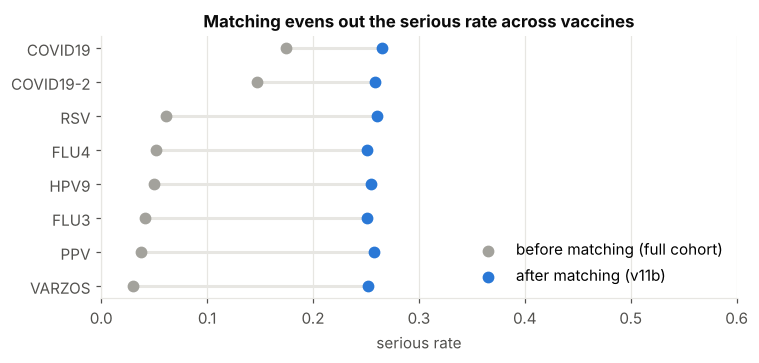

In [14]:
def band(a):
    a = pd.to_numeric(a, errors="coerce")
    return pd.cut(a, [-1, 17, 49, 64, 200], labels=["0-17", "18-49", "50-64", "65+"]).astype(str).replace("nan", "unknown")
top_vax = full.vax_type.value_counts().head(8).index
before = full[full.vax_type.isin(top_vax)].groupby("vax_type").serious.apply(lambda s: (s == "1").mean())
after = df[df.vax_type.isin(top_vax)].groupby("vax_type").serious.apply(lambda s: (s == "1").mean())
order = before.sort_values().index
fig, ax = plt.subplots(figsize=(7, 3.4))
for i, v in enumerate(order):
    ax.plot([before[v], after[v]], [i, i], color=GRID, lw=2, zorder=1)
ax.scatter(before[order], range(len(order)), color=GRAY, s=45, zorder=2, label="before matching (full cohort)")
ax.scatter(after[order], range(len(order)), color=BLUE, s=45, zorder=3, label="after matching (v11b)")
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.set_xlabel("serious rate"); ax.set_xlim(0, 0.6)
ax.grid(axis="y", visible=False); ax.legend(frameon=False, loc="lower right")
ax.set_title("Matching evens out the serious rate across vaccines"); plt.tight_layout(); plt.show()

**Insight.** Before matching, the vaccine alone told a lot (3% serious for shingles, 17% for COVID-19). After matching, every vaccine sits near 26%, so the model has to read the text. This is what raised the TAR gain (results notebook).

## Part C — the final dataset

### C1. Columns at a glance

In [15]:
y = df.serious.astype(int).to_numpy()
desc = {"age_years": "Patient age in years", "sex": "Patient sex", "state": "US state", "onset_days": "Days from vaccination to first symptom",
        "vax_type": "Vaccine type (first listed)", "vax_manu": "Manufacturer", "vax_dose_series": "Dose number", "vax_route": "Route",
        "vax_site": "Injection site", "n_vaccines": "Vaccines given at the visit", "admin_by": "Facility type", "report_year": "Year of the report",
        "patient_background": "History, illness, medications, allergies", "narrative_onset": "Opening of the reaction narrative",
        "serious": "Target", "report_id": "VAERS id (dropped by the benchmark)"}
pd.DataFrame([{"column": col, "role": "target" if col == "serious" else "id" if col == "report_id" else "text" if col in TEXT else
               "numeric" if col in NUM else "categorical", "unique values": df[col].nunique(), "meaning": desc[col]}
              for col in df.columns]).set_index("column")

,role,unique values,meaning
column,,,
age_years,numeric,134,Patient age in years
sex,categorical,3,Patient sex
state,categorical,59,US state
onset_days,numeric,44,Days from vaccination to first symptom
vax_type,categorical,54,Vaccine type (first listed)
vax_manu,categorical,24,Manufacturer
vax_dose_series,categorical,9,Dose number
vax_route,categorical,10,Route
vax_site,categorical,12,Injection site


### C2. How much each column predicts on its own (out-of-fold AUROC; 0.5 = nothing)

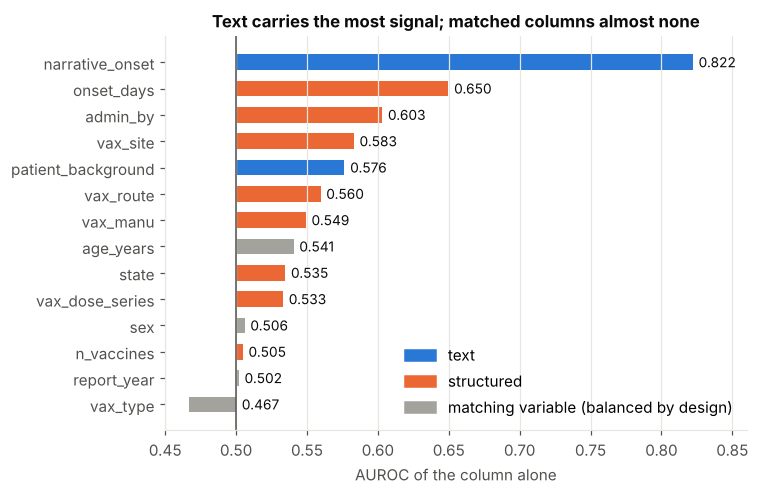

In [16]:
def single_column_auroc(values, folds=5):
    v = pd.Series(values)
    x = pd.to_numeric(v, errors="coerce")
    if x.notna().mean() > 0.5:                      # numeric column
        if x.nunique() > 20:
            x = pd.qcut(x, 10, labels=False, duplicates="drop")
        v = x.astype("Int64").astype(str).where(x.notna(), "missing")
    oof = np.zeros(len(v))
    for tr, te in StratifiedKFold(folds, shuffle=True, random_state=42).split(v, y):
        rates = pd.Series(y[tr]).groupby(v.iloc[tr].to_numpy()).mean()
        oof[te] = v.iloc[te].map(rates).fillna(y[tr].mean()).to_numpy()
    return roc_auc_score(y, oof)
def text_auroc(texts):
    X = TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True).fit_transform(texts)
    oof = np.zeros(len(y))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=42).split(X, y):
        oof[te] = LogisticRegression(max_iter=3000).fit(X[tr], y[tr]).decision_function(X[te])
    return roc_auc_score(y, oof)
scores = {col: single_column_auroc(df[col]) for col in NUM + CAT}
scores.update({col: text_auroc(df[col]) for col in TEXT})
s = pd.Series(scores).sort_values()
matched = {"vax_type", "report_year", "age_years", "sex"}
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(s.index, s - 0.5, left=0.5, height=0.6, color=[BLUE if i in TEXT else GRAY if i in matched else ORANGE for i in s.index])
for i, v in enumerate(s):
    ax.text(max(v, 0.5) + 0.004, i, f"{v:.3f}", va="center", fontsize=9, color=INK)
ax.axvline(0.5, color=INK2, lw=1); ax.set_xlim(0.45, 0.86); ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="text"), Patch(color=ORANGE, label="structured"),
                   Patch(color=GRAY, label="matching variable (balanced by design)")], frameon=False, loc="lower right")
ax.set_xlabel("AUROC of the column alone"); ax.set_title("Text carries the most signal; matched columns almost none")
plt.tight_layout(); plt.show()

**Insight.** The excerpt is the strongest input (0.82). Matched columns sit at 0.50 by design; the table's own signal is onset delay (0.65), facility type, site and route.

### C3. Association between columns and with the target (Cramér's V)

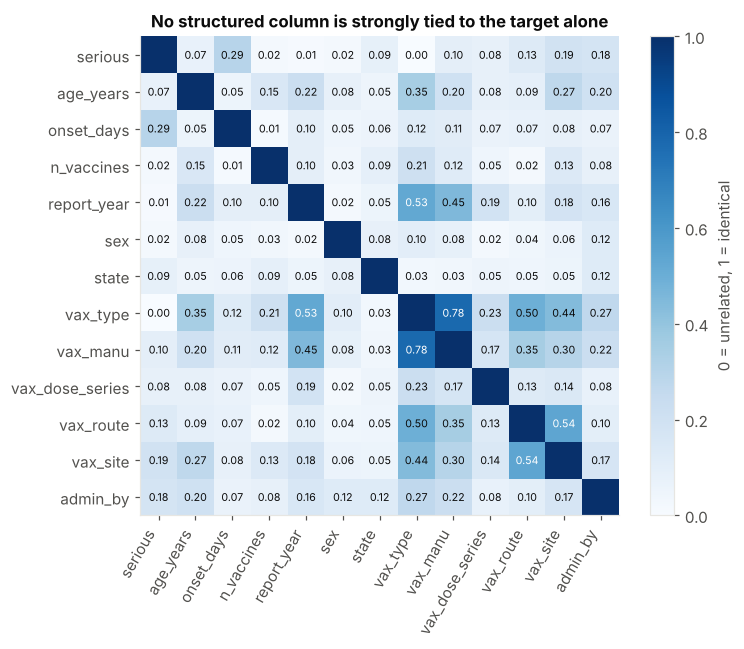

In [17]:
def cramers_v(a, b):
    tab = pd.crosstab(a, b).to_numpy(); n = tab.sum()
    e = tab.sum(1, keepdims=True) * tab.sum(0, keepdims=True) / n
    r, k = tab.shape; phi2 = max(0, ((tab - e) ** 2 / e).sum() / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(1e-9, min(kc - 1, rc - 1)))
cat = {}
for col in NUM + CAT:
    x = pd.to_numeric(df[col], errors="coerce") if col in NUM else df[col]
    if col in NUM and x.nunique() > 20:
        x = pd.qcut(x, 10, labels=False, duplicates="drop")
    cat[col] = x.astype(str)
cat["serious"] = df.serious
cols = ["serious"] + NUM + CAT
V = pd.DataFrame([[cramers_v(cat[a], cat[b]) for b in cols] for a in cols], index=cols, columns=cols)
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(V, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=60, ha="right"); ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        if i != j:
            ax.text(j, i, f"{V.iat[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if V.iat[i, j] > 0.5 else INK)
ax.grid(False); fig.colorbar(im, fraction=0.04, label="0 = unrelated, 1 = identical")
ax.set_title("No structured column is strongly tied to the target alone"); plt.tight_layout(); plt.show()

**Insight.** The target row is pale (strongest: onset days 0.29). Vaccine type, manufacturer, route and site move together, as expected: a vaccine fixes its maker and route.

### C4. The text columns

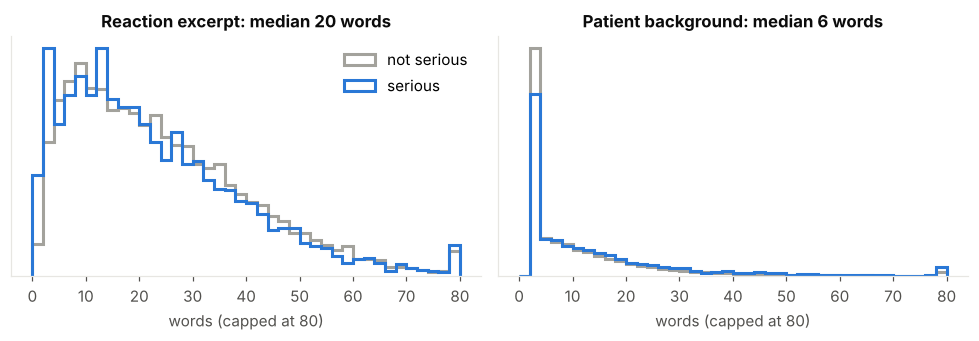

In [18]:
words = {col: df[col].str.split().str.len() for col in TEXT}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, col, title in [(axes[0], "narrative_onset", "Reaction excerpt"), (axes[1], "patient_background", "Patient background")]:
    w = words[col].clip(upper=80); bins = np.arange(0, 82, 2)
    ax.hist(w[y == 0], bins=bins, color=GRAY, histtype="step", lw=2, density=True, label="not serious")
    ax.hist(w[y == 1], bins=bins, color=BLUE, histtype="step", lw=2, density=True, label="serious")
    ax.set_title(f"{title}: median {int(words[col].median())} words"); ax.set_xlabel("words (capped at 80)"); ax.set_yticks([]); ax.grid(visible=False)
axes[0].legend(frameon=False); plt.tight_layout(); plt.show()

**Insight.** The excerpt is real free text (median 20 words) with the same length in both classes. The background is short and "none reported" in a third of reports.

### C5. Leakage checks

In [19]:
patterns = {"outcome words": bv.OUTCOME_SENTENCE, "care / treatment words": bv.CARE_SENTENCE,
            "chart / ICD wording": bv.CHART_SENTENCE, "procedures": rv.EXTRA_CARE}
checks = [{"check": f"excerpts containing {k}", "result": int(df.narrative_onset.str.contains(p).sum()), "want": "0"} for k, p in patterns.items()]
checks += [{"check": "AUROC of excerpt length alone", "result": round(roc_auc_score(y, df.narrative_onset.str.len()), 3), "want": "about 0.5"},
           {"check": "rows sharing an identical excerpt", "result": f"{df.narrative_onset.duplicated(keep=False).mean():.1%}", "want": "small"}]
pd.DataFrame(checks).set_index("check")

,result,want
check,,
excerpts containing outcome words,0,0
excerpts containing care / treatment words,0,0
excerpts containing chart / ICD wording,0,0
excerpts containing procedures,0,0
AUROC of excerpt length alone,0.469,about 0.5
rows sharing an identical excerpt,3.5%,small


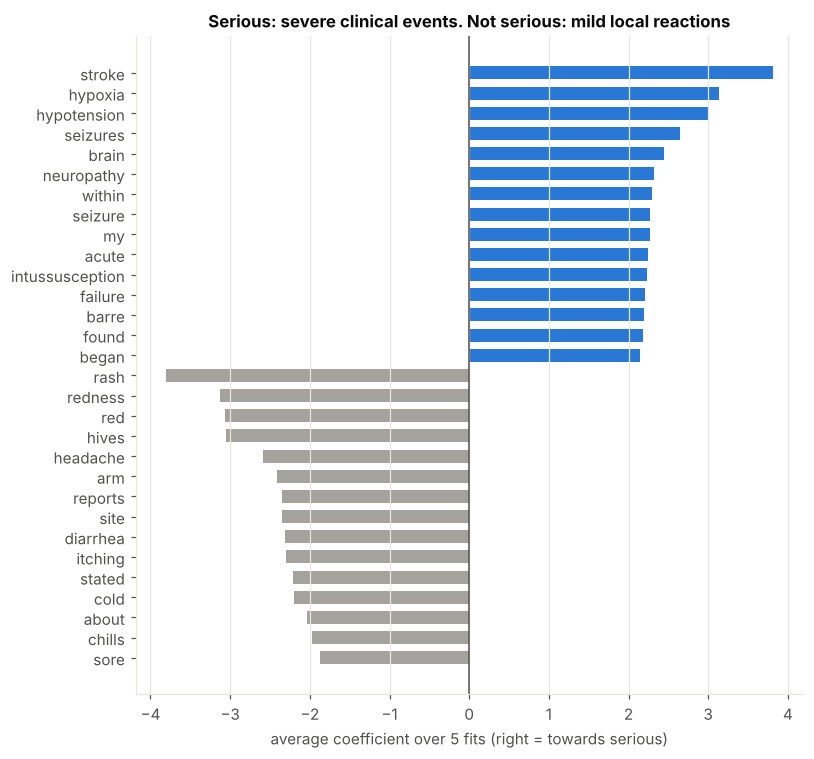

care / outcome words among the top 40 serious terms: 0


In [20]:
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b")
X = vec.fit_transform(df.narrative_onset)
C = np.vstack([LogisticRegression(max_iter=3000).fit(X[tr], y[tr]).coef_[0]
               for tr, _ in StratifiedKFold(5, shuffle=True, random_state=42).split(X, y)])
terms = pd.DataFrame({"term": vec.get_feature_names_out(), "coef": C.mean(0), "stable": (np.sign(C) == np.sign(C.mean(0))).all(0),
                      "reports": np.asarray((X > 0).sum(0)).ravel()})
good = terms[terms.stable & (terms.reports >= 25)]
show = pd.concat([good.nsmallest(15, "coef").iloc[::-1], good.nlargest(15, "coef").iloc[::-1]])
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.barh(show.term, show.coef, color=[BLUE if v > 0 else GRAY for v in show.coef], height=0.65)
ax.axvline(0, color=INK2, lw=1); ax.grid(axis="y", visible=False)
ax.set_xlabel("average coefficient over 5 fits (right = towards serious)")
ax.set_title("Serious: severe clinical events. Not serious: mild local reactions"); plt.tight_layout(); plt.show()
print("care / outcome words among the top 40 serious terms:",
      int(good.nlargest(40, "coef").term.str.contains("|".join(p.pattern for p in patterns.values()), case=False).sum()))

**Insight.** No care or outcome words remain, and length is not a shortcut. What predicts *serious* is the kind of reaction (stroke, hypoxia, seizures, Guillain–Barré); *not serious* is mild and local (rash, redness, sore arm). A few writing-style words appear too (*my*, *stated*).

## Summary

| Step | Finding | Rule |
|---|---|---|
| A1 | ~4 in 5 serious reports are hospital stays | No input may reveal hospital care |
| A2 | Manufacturer reports are templated, with a different serious rate (5.6% vs 17.0%) | Dropped |
| A3 | Late-onset COVID reports are serious by reporting rule | Onset 0–42 days; no infection reports |
| A4 | Background fields mostly empty | Merged into one text column |
| A5 | Full narrative names the hospital course | Keep only its opening |
| B | 208,309 → 18,859 reports, 26% serious | Matched controls; care clean-ups 2 and 3 |
| C | Text 0.82 alone; zero care words left | Final dataset passes the leakage checks |